In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

print("Bibliotecas carregadas com sucesso!")


Bibliotecas carregadas com sucesso!


In [3]:

# Criando 5.000 transações financeiras simuladas

np.random.seed(42)

n = 5000

valor = np.random.uniform(10, 10000, n)
horario = np.random.randint(0, 24, n)
internacional = np.random.randint(0, 2, n)

# Regras fictícias para simular fraudes
risco = (
    (valor > 7000).astype(int)
    + (horario < 5).astype(int)
    + internacional
)

fraude = (risco >= 2).astype(int)

dados = pd.DataFrame({
    "valor": valor,
    "horario": horario,
    "internacional": internacional,
    "fraude": fraude
})

print(dados.head())
print("\nTotal de transações:", len(dados))
print("Fraudes simuladas:", dados["fraude"].sum())


         valor  horario  internacional  fraude
0  3751.655787       18              1       0
1  9507.635921        7              0       0
2  7322.619479        6              1       1
3  5990.598257       15              1       0
4  1568.626218       18              0       0

Total de transações: 5000
Fraudes simuladas: 1290


In [4]:

# Separar os dados
X = dados[["valor", "horario", "internacional"]]
y = dados["fraude"]

# Separar dados para treinamento e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Criar o modelo de Inteligência Artificial
modelo = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Treinar a IA
modelo.fit(X_treino, y_treino)

# Fazer previsões
previsoes = modelo.predict(X_teste)

# Mostrar resultados
print("IA treinada com sucesso!")
print()
print(classification_report(y_teste, previsoes))


IA treinada com sucesso!

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       742
           1       1.00      1.00      1.00       258

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



In [5]:

# Nova transação para análise
nova_transacao = pd.DataFrame([{
    "valor": 9500,
    "horario": 2,
    "internacional": 1
}])

# IA faz a previsão
resultado = modelo.predict(nova_transacao)[0]

# Probabilidade estimada pelo modelo
probabilidade = modelo.predict_proba(nova_transacao)[0][1]

print("=== AI FRAUD DETECTION SYSTEM ===")
print("Valor: R$ 9.500,00")
print("Horário: 02:00")
print("Transação internacional: Sim")
print()

if resultado == 1:
    print("ALERTA: Transação suspeita!")
else:
    print("Transação classificada como normal.")

print(f"Pontuação de risco: {probabilidade * 100:.2f}%")



=== AI FRAUD DETECTION SYSTEM ===
Valor: R$ 9.500,00
Horário: 02:00
Transação internacional: Sim

ALERTA: Transação suspeita!
Pontuação de risco: 100.00%


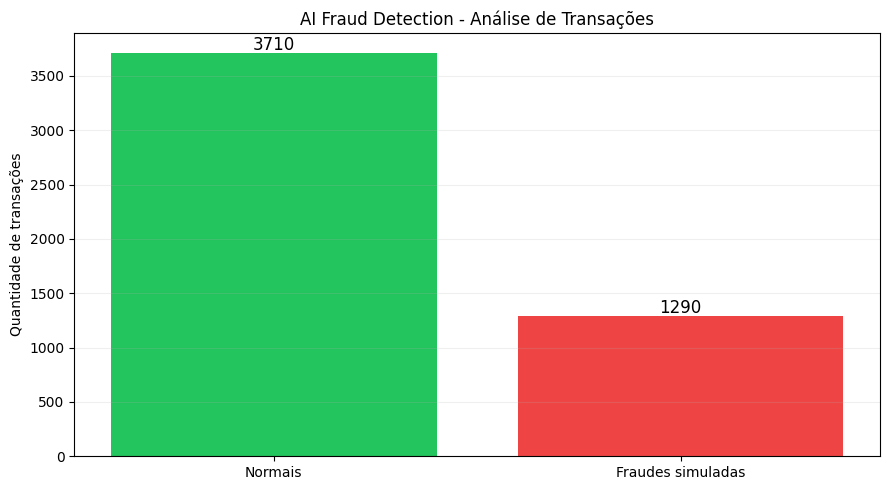

In [6]:

# Dashboard de detecção de fraudes

import matplotlib.pyplot as plt

# Contar transações por categoria
contagem = dados["fraude"].value_counts()

normais = contagem.get(0, 0)
fraudes = contagem.get(1, 0)

# Criar gráfico
plt.figure(figsize=(9, 5))

barras = plt.bar(
    ["Normais", "Fraudes simuladas"],
    [normais, fraudes],
    color=["#22c55e", "#ef4444"]
)

# Mostrar números acima das barras
for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 30,
        str(int(altura)),
        ha="center",
        fontsize=12
    )

plt.title("AI Fraud Detection - Análise de Transações")
plt.ylabel("Quantidade de transações")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.show()


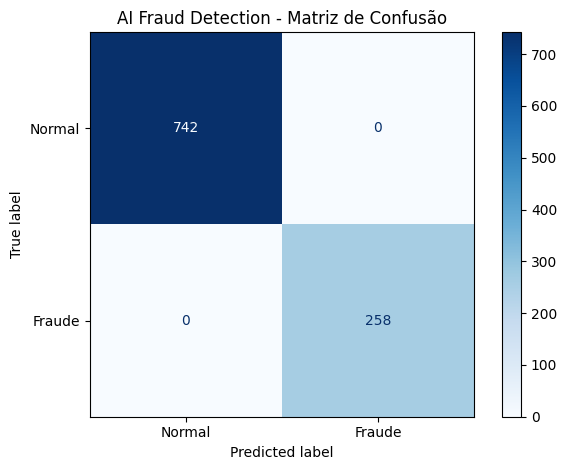

In [7]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Gerar matriz de confusão
ConfusionMatrixDisplay.from_predictions(
    y_teste,
    previsoes,
    display_labels=["Normal", "Fraude"],
    cmap="Blues",
    values_format="d"
)

plt.title("AI Fraud Detection - Matriz de Confusão")
plt.tight_layout()
plt.show()


In [8]:

import joblib

# Salvar o modelo treinado
joblib.dump(modelo, "fraud_detection_model.pkl")

print("Modelo de IA salvo com sucesso!")


Modelo de IA salvo com sucesso!


In [9]:
dados_reais = pd.read_csv("creditcard.csv")

print("Dataset carregado com sucesso!")
print("Total de transações:", len(dados_reais))
print("Fraudes:", dados_reais["Class"].sum())

display(dados_reais.head())


Dataset carregado com sucesso!
Total de transações: 134763
Fraudes: 262.0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [10]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Separar características e resultado
X_real = dados_reais.drop("Class", axis=1)
y_real = dados_reais["Class"]

# Separar 80% para treino e 20% para teste
X_treino_real, X_teste_real, y_treino_real, y_teste_real = train_test_split(
    X_real,
    y_real,
    test_size=0.2,
    random_state=42,
    stratify=y_real
)

# Criar modelo de Machine Learning
modelo_real = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Treinar modelo
modelo_real.fit(X_treino_real, y_treino_real)

# Fazer previsões
previsoes_reais = modelo_real.predict(X_teste_real)

# Calcular probabilidades
probabilidades = modelo_real.predict_proba(X_teste_real)[:, 1]

# Avaliar resultados
print("IA treinada com dados reais!")
print()
print(classification_report(y_teste_real, previsoes_reais))
print("ROC-AUC:", round(
    roc_auc_score(y_teste_real, probabilidades), 4
))


ValueError: Input y contains NaN.

In [11]:

print("Total de linhas:", len(dados_reais))
print("Total de colunas:", len(dados_reais.columns))

print("\nDistribuição das classes:")
print(dados_reais["Class"].value_counts(dropna=False))

print("\nValores ausentes por coluna:")
print(dados_reais.isna().sum()[
    dados_reais.isna().sum() > 0
])


Total de linhas: 134763
Total de colunas: 31

Distribuição das classes:
Class
0.0    134500
1.0       262
NaN         1
Name: count, dtype: int64

Valores ausentes por coluna:
V22       1
V23       1
V24       1
V25       1
V26       1
V27       1
V28       1
Amount    1
Class     1
dtype: int64


In [12]:

import pandas as pd

# Recarregar o arquivo original
dados_reais = pd.read_csv("creditcard.csv")

print("Total de transações:", len(dados_reais))
print("Total de fraudes:", int(dados_reais["Class"].sum()))
print("Valores ausentes:", dados_reais.isna().sum().sum())

if (
    len(dados_reais) == 284807
    and dados_reais.isna().sum().sum() == 0
):
    print("Dataset completo! Pronto para treinar a IA.")
else:
    print("ATENÇÃO: precisamos verificar o arquivo.")


Total de transações: 162557
Total de fraudes: 356
Valores ausentes: 3
ATENÇÃO: precisamos verificar o arquivo.


In [13]:

!pip install -q kagglehub

import kagglehub
import pandas as pd
import os

# Baixar dataset diretamente do Kaggle
caminho = kagglehub.dataset_download(
    "mlg-ulb/creditcardfraud"
)

# Encontrar arquivo CSV
arquivo = os.path.join(caminho, "creditcard.csv")

# Carregar dataset
dados_reais = pd.read_csv(arquivo)

print("Total de transações:", len(dados_reais))
print("Total de fraudes:", int(dados_reais["Class"].sum()))
print("Valores ausentes:", dados_reais.isna().sum().sum())


Using Colab cache for faster access to the 'creditcardfraud' dataset.
Total de transações: 284807
Total de fraudes: 492
Valores ausentes: 0


In [14]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, average_precision_score

# Separar características e classificação
X_real = dados_reais.drop("Class", axis=1)
y_real = dados_reais["Class"].astype(int)

# Separar dados de treino e teste
X_treino_real, X_teste_real, y_treino_real, y_teste_real = train_test_split(
    X_real,
    y_real,
    test_size=0.2,
    random_state=42,
    stratify=y_real
)

# Criar modelo Random Forest
modelo_real = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Treinar a IA
modelo_real.fit(X_treino_real, y_treino_real)

# Fazer previsões
previsoes_reais = modelo_real.predict(X_teste_real)

# Calcular pontuações
probabilidades = modelo_real.predict_proba(
    X_teste_real
)[:, 1]

# Mostrar resultados
print("IA treinada com dados reais!")
print()
print(classification_report(
    y_teste_real,
    previsoes_reais
))

print("PR-AUC (Average Precision):",
      round(average_precision_score(
          y_teste_real,
          probabilidades
      ), 4))



IA treinada com dados reais!

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.81      0.82        98

    accuracy                           1.00     56962
   macro avg       0.92      0.90      0.91     56962
weighted avg       1.00      1.00      1.00     56962

PR-AUC (Average Precision): 0.832


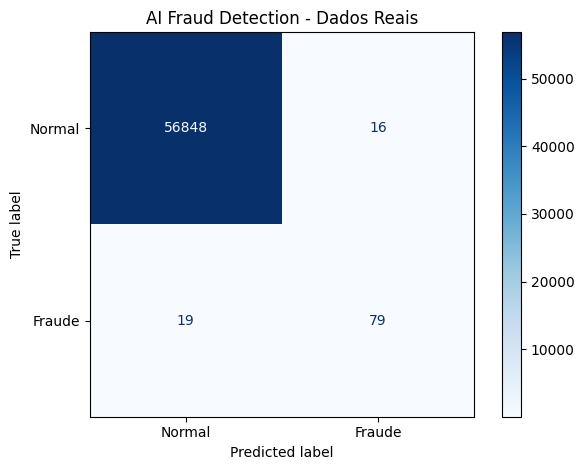

In [15]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Matriz de confusão do modelo real
ConfusionMatrixDisplay.from_predictions(
    y_teste_real,
    previsoes_reais,
    display_labels=["Normal", "Fraude"],
    cmap="Blues",
    values_format="d"
)

plt.title("AI Fraud Detection - Dados Reais")
plt.tight_layout()
plt.show()


In [16]:

import joblib

# Salvar o modelo treinado com dados reais
joblib.dump(
    modelo_real,
    "fraud_detection_real_model.pkl"
)

print("Modelo real salvo com sucesso!")


Modelo real salvo com sucesso!


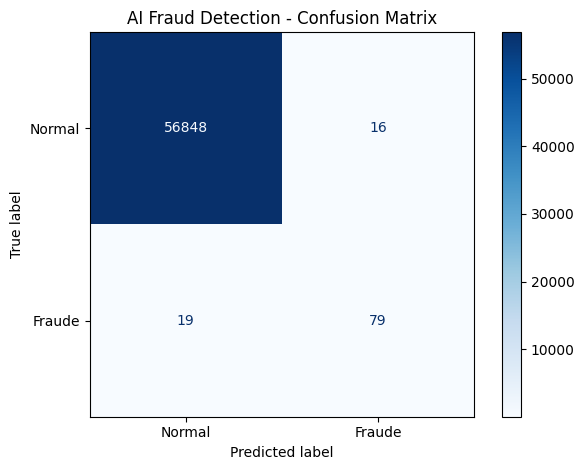

Arquivos de resultados salvos!


In [17]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    average_precision_score
)

# Salvar matriz de confusão
ConfusionMatrixDisplay.from_predictions(
    y_teste_real,
    previsoes_reais,
    display_labels=["Normal", "Fraude"],
    cmap="Blues",
    values_format="d"
)

plt.title("AI Fraud Detection - Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

# Salvar métricas em arquivo
with open("metrics.txt", "w") as arquivo:
    arquivo.write("AI FRAUD DETECTION SYSTEM\n\n")
    arquivo.write(classification_report(
        y_teste_real,
        previsoes_reais
    ))
    arquivo.write("\nPR-AUC: ")
    arquivo.write(str(round(
        average_precision_score(
            y_teste_real,
            probabilidades
        ), 4
    )))

print("Arquivos de resultados salvos!")
